# Chapter 4 — Building Models with Distance Metrics and Nearest Neighbors

> Reproduction notebook for **scikit-learn Cookbook, Third Edition** (John Sukup, Packt 2025).

## Chapter Summary

Humans judge similarity naturally (a Toyota is a car, not a cat). Machine learning formalises this with **distance metrics**, and the simplest model built on that idea is **k-nearest neighbours (KNN)**.

| Topic | Key points |
|---|---|
| Distance metrics | Euclidean (straight line), Manhattan (grid / absolute differences), Minkowski (generalisation with parameter *p*) |
| KNN | Classify a new point by majority vote of its *k* nearest training points (regression: average) |
| Choosing *k* | Cross-validation, elbow method; small *k* = noisy, large *k* = over-smoothed |
| Hyperparameter tuning | `GridSearchCV` (exhaustive) and `RandomizedSearchCV` (sampled) |
| Evaluation | Cross-validation scores, learning curves, confusion matrix, classification report |
| Imbalanced data | Prefer precision-recall / ROC-AUC; consider resampling |

## 1. Introduction to distance metrics

**Theory.** Distance measures how (dis)similar two points are in feature space. For points $a$ and $b$ with $n$ features:

* **Euclidean (L2):** $d=\sqrt{\sum_i (a_i-b_i)^2}$ — straight-line ("as the crow flies") distance; the default; sensitive to outliers and to scale.
* **Manhattan (L1):** $d=\sum_i |a_i-b_i|$ — city-block distance; less sensitive to outliers.
* **Minkowski:** $d=\left(\sum_i |a_i-b_i|^p\right)^{1/p}$ — generalises both: $p=1$ gives Manhattan, $p=2$ gives Euclidean.

## 2. Understanding KNN

**Theory.** KNN is a supervised method (classification and regression). It has **no real training step**: it stores the data, and at prediction time it

1. computes the distance from the new point to all training points,
2. takes the **k** nearest,
3. votes (classification) or averages (regression).

Small *k* → sensitive to noise (overfitting); large *k* → smoother boundaries that may miss local patterns (underfitting).

In [1]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split

iris = load_iris()
X = iris.data
y = iris.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=2024
)

In [2]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

knn = KNeighborsClassifier(n_neighbors=3)
knn.fit(X_train, y_train)

y_pred = knn.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred))

Accuracy: 0.9333333333333333


**Choosing *k*.** Use cross-validation, or the **elbow method**: plot accuracy against *k* and look for the point after which gains diminish. The book also mentions that other metrics (e.g. Hamming for categorical data) may work better depending on the data. The next cell is a small illustration of the elbow idea (added by me).

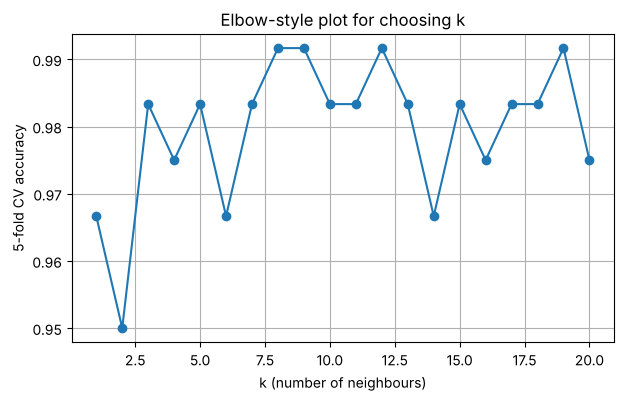

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import cross_val_score

ks = range(1, 21)
cv_means = [cross_val_score(KNeighborsClassifier(n_neighbors=k), X_train, y_train, cv=5).mean() for k in ks]

plt.figure(figsize=(7, 4))
plt.plot(ks, cv_means, marker="o")
plt.xlabel("k (number of neighbours)"); plt.ylabel("5-fold CV accuracy")
plt.title("Elbow-style plot for choosing k"); plt.grid(True)
plt.show()

## 3. Distance metrics overview — which metric for which data?

We create two synthetic datasets (noisy **circles**, and a **checkerboard** grid) and compare KNN with `euclidean`, `manhattan` and `minkowski` metrics.

> The book's code uses `KNeighborsClassifier` and `accuracy_score` here without re-importing them; they are imported explicitly below.
>
> Note: `metric="minkowski"` uses `p=2` by default, so it behaves exactly like Euclidean unless you change `p`.

In [4]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import make_circles
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

n_samples = 300

# Circular dataset with high noise
X_circles, y_circles = make_circles(n_samples=n_samples, noise=0.3, factor=0.3, random_state=2024)
X_circles_train, X_circles_test, y_circles_train, y_circles_test = train_test_split(
    X_circles, y_circles, test_size=0.2, random_state=2024
)

# Checkerboard pattern dataset
x = np.linspace(0, 4, int(np.sqrt(n_samples)))
y = np.linspace(0, 4, int(np.sqrt(n_samples)))
xx, yy = np.meshgrid(x, y)
X_moons = np.column_stack((xx.ravel(), yy.ravel()))
y_moons = np.mod(np.floor(xx.ravel()) + np.floor(yy.ravel()), 2)
X_moons_train, X_moons_test, y_moons_train, y_moons_test = train_test_split(
    X_moons, y_moons, test_size=0.2, random_state=2024
)

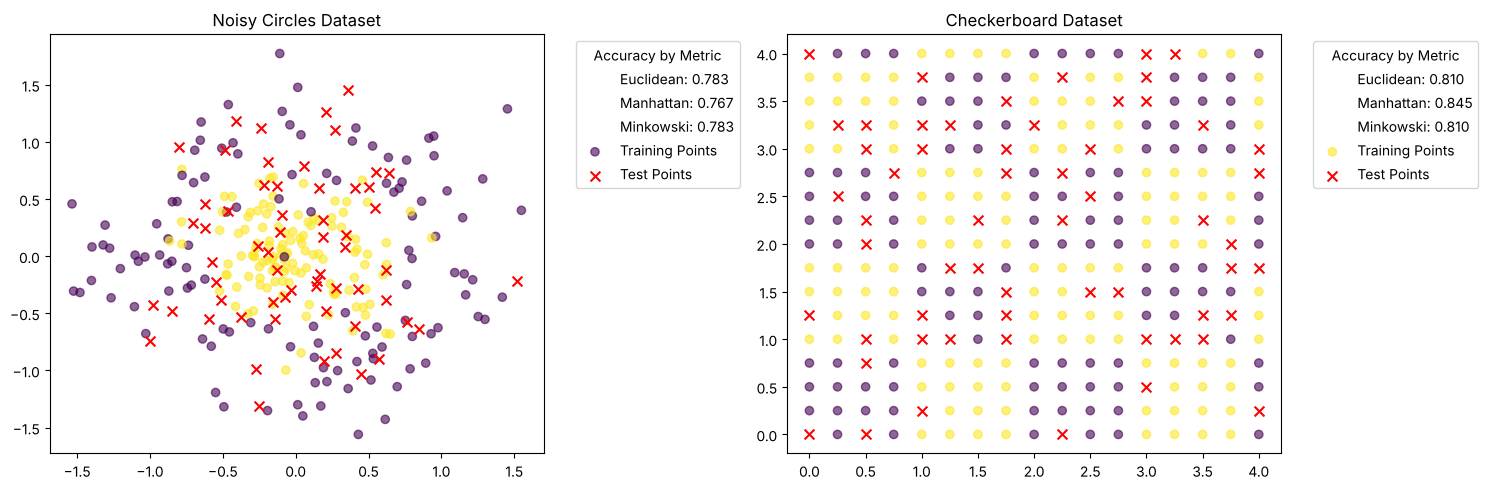

In [5]:
metrics = ['euclidean', 'manhattan', 'minkowski']
results = {'circles': {}, 'moons': {}}

for metric in metrics:
    # circles dataset
    knn_circles = KNeighborsClassifier(n_neighbors=3, metric=metric)
    knn_circles.fit(X_circles_train, y_circles_train)
    results['circles'][metric] = accuracy_score(y_circles_test, knn_circles.predict(X_circles_test))

    # checkerboard dataset
    knn_moons = KNeighborsClassifier(n_neighbors=3, metric=metric)
    knn_moons.fit(X_moons_train, y_moons_train)
    results['moons'][metric] = accuracy_score(y_moons_test, knn_moons.predict(X_moons_test))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# ---- circles
s1 = ax1.scatter(X_circles_train[:, 0], X_circles_train[:, 1], c=y_circles_train,
                 cmap='viridis', alpha=0.6, label='Training Points')
s1t = ax1.scatter(X_circles_test[:, 0], X_circles_test[:, 1], color='red',
                  marker='x', s=50, label='Test Points')
ax1.set_title('Noisy Circles Dataset')
lines1 = [plt.Line2D([0], [0], color='white') for _ in metrics]
text1 = [f"Euclidean: {results['circles']['euclidean']:.3f}",
         f"Manhattan: {results['circles']['manhattan']:.3f}",
         f"Minkowski: {results['circles']['minkowski']:.3f}"]
ax1.legend(lines1 + [s1, s1t], text1 + ['Training Points', 'Test Points'],
           title='Accuracy by Metric', bbox_to_anchor=(1.05, 1), loc='upper left')

# ---- checkerboard
s2 = ax2.scatter(X_moons_train[:, 0], X_moons_train[:, 1], c=y_moons_train,
                 cmap='viridis', alpha=0.6, label='Training Points')
s2t = ax2.scatter(X_moons_test[:, 0], X_moons_test[:, 1], color='red',
                  marker='x', s=50, label='Test Points')
ax2.set_title('Checkerboard Dataset')
lines2 = [plt.Line2D([0], [0], color='white') for _ in metrics]
text2 = [f"Euclidean: {results['moons']['euclidean']:.3f}",
         f"Manhattan: {results['moons']['manhattan']:.3f}",
         f"Minkowski: {results['moons']['minkowski']:.3f}"]
ax2.legend(lines2 + [s2, s2t], text2 + ['Training Points', 'Test Points'],
           title='Accuracy by Metric', bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()

**Impact on model performance (from the book).**

* *Sensitivity to scale* – Euclidean distance is strongly affected by feature scales, so standardize/normalize before KNN.
* *Dimensionality* – in high dimensions distances lose meaning (the **curse of dimensionality**); some metrics cope better than others.
* Choose the metric from the nature of your data (continuous vs categorical), try several, and compare them with cross-validation.

## 4. Hyperparameter tuning in KNN

**Theory.** *Parameters* are learned during training (e.g. slope $m$ and intercept $b$ in $y=mx+b$); *hyperparameters* tell the model **how to learn** (e.g. *k*).

* **Grid search** tests *all* combinations of a grid. Combined with **cross-validation**, each combination is scored on several train/validation splits, giving a robust estimate and reducing overfitting.
* **Randomized search** samples combinations at random — cheaper for big search spaces.

We tune `n_neighbors`, `weights` (`uniform` vs `distance`: closer neighbours count more) and `metric`.

In [6]:
from sklearn.model_selection import GridSearchCV

knn = KNeighborsClassifier()

param_grid = {
    'n_neighbors': [3, 5, 7, 9, 11],
    'weights': ['uniform', 'distance'],
    'metric': ['euclidean', 'manhattan'],
}

grid_search = GridSearchCV(knn, param_grid, cv=5, scoring='accuracy')
grid_search.fit(X_train, y_train)

print("Best parameters:", grid_search.best_params_)
print("Best cross-validation score:", grid_search.best_score_)

Best parameters: {'metric': 'euclidean', 'n_neighbors': 9, 'weights': 'uniform'}
Best cross-validation score: 0.9916666666666668


In [7]:
# "There's more": randomized search samples a subset of the combinations
from sklearn.model_selection import RandomizedSearchCV

rand_search = RandomizedSearchCV(
    KNeighborsClassifier(), param_grid, n_iter=10, cv=5, scoring='accuracy', random_state=2024
)
rand_search.fit(X_train, y_train)
print("Randomized search best:", rand_search.best_params_, round(rand_search.best_score_, 4))

Randomized search best: {'weights': 'uniform', 'n_neighbors': 9, 'metric': 'euclidean'} 0.9917


## 5. Evaluating KNN performance

**Theory — evaluation tools**

* **Learning curve** – score vs. training-set size; reveals under/overfitting and whether more data helps.
* **Confusion matrix** – counts of true positives (TP), true negatives (TN), false positives (FP), false negatives (FN).
* **Classification report** combines:
  * Precision $=\frac{TP}{TP+FP}$
  * Recall $=\frac{TP}{TP+FN}$
  * F1-score $=2\times\frac{Precision\times Recall}{Precision+Recall}$ (harmonic mean)
  * Accuracy $=\frac{TP+TN}{TP+TN+FP+FN}$
  * Macro avg (unweighted mean over classes) and weighted avg (weighted by class support)

> In the book some imports (`cross_val_score`, `classification_report`, `pandas`, `numpy`, `matplotlib`) are assumed from earlier cells; they are imported here to make the notebook self-contained.

In [8]:
import pandas as pd
import seaborn as sns
from sklearn.model_selection import cross_val_score, learning_curve
from sklearn.metrics import confusion_matrix, classification_report

# 1) Cross-validation scores of the tuned model
cv_scores = cross_val_score(grid_search.best_estimator_, X_train, y_train, cv=5)
print("Cross-validation scores:", cv_scores)
print("Mean CV score:", cv_scores.mean())
print("Standard deviation:", cv_scores.std())

Cross-validation scores: [0.95833333 1.         1.         1.         1.        ]
Mean CV score: 0.9916666666666668
Standard deviation: 0.016666666666666653


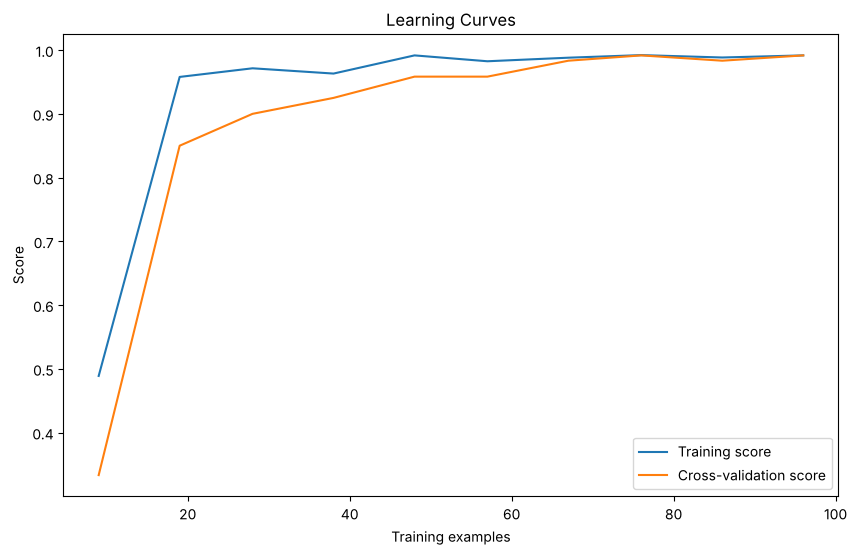

In [9]:
# 2) Learning curves
train_sizes, train_scores, test_scores = learning_curve(
    grid_search.best_estimator_, X_train, y_train,
    train_sizes=np.linspace(0.1, 1.0, 10), cv=5,
)

plt.figure(figsize=(10, 6))
plt.plot(train_sizes, np.mean(train_scores, axis=1), label='Training score')
plt.plot(train_sizes, np.mean(test_scores, axis=1), label='Cross-validation score')
plt.xlabel('Training examples')
plt.ylabel('Score')
plt.legend(loc='best')
plt.title('Learning Curves')
plt.show()

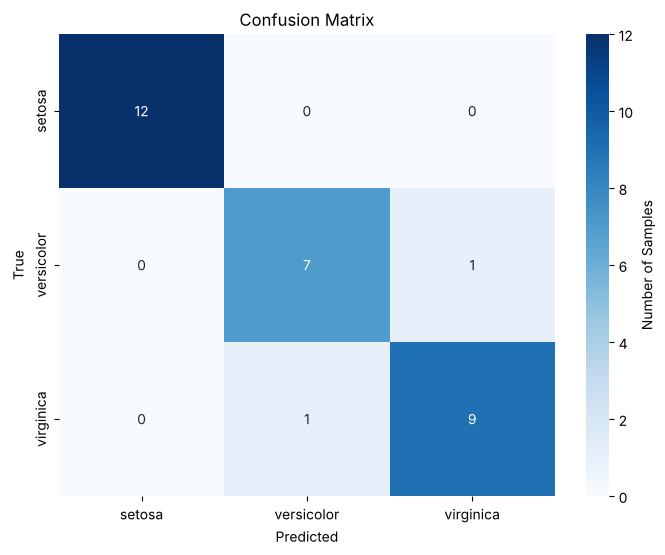

In [10]:
# 3) Confusion matrix on the test set
y_pred = grid_search.best_estimator_.predict(X_test)
class_names = iris.target_names

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names,
            cbar_kws={'label': 'Number of Samples'})
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()

In [11]:
# 4) Classification report as a styled DataFrame
report_dict = classification_report(y_test, y_pred, target_names=class_names, output_dict=True)
report_df = pd.DataFrame(report_dict).transpose()

styled_df = (report_df.style
    .background_gradient(cmap='Blues', subset=['precision', 'recall', 'f1-score'])
    .format({'precision': '{:.3f}', 'recall': '{:.3f}', 'f1-score': '{:.3f}', 'support': '{:.0f}'}))
display(styled_df)

,precision,recall,f1-score,support
setosa,1.000,1.000,1.000,12
versicolor,0.875,0.875,0.875,8
virginica,0.900,0.900,0.900,10
accuracy,0.933,0.933,0.933,1
macro avg,0.925,0.925,0.925,30
weighted avg,0.933,0.933,0.933,30


> The book notes that 100 % scores for *setosa* would normally be suspicious, but this toy dataset is easy even for simple models. It also reminds us that "very good" performance only has meaning in the context of the business problem.

**Imbalanced datasets:** when one class heavily outnumbers another, use precision-recall curves or ROC-AUC instead of accuracy alone, and consider resampling (oversample the minority / undersample the majority class).

## 6. Practical exercises with KNN models

The book gives steps only. Below are three compact implementations, using different datasets than Iris.

### Exercise 1 — Build a KNN classifier (Wine dataset, with preprocessing)

In [12]:
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

wine = load_wine()
Xw_train, Xw_test, yw_train, yw_test = train_test_split(
    wine.data, wine.target, test_size=0.3, random_state=2024, stratify=wine.target)

# KNN is distance-based -> scale first
knn_pipe = Pipeline([('scaler', StandardScaler()), ('knn', KNeighborsClassifier(n_neighbors=5))])
knn_pipe.fit(Xw_train, yw_train)
print("Wine accuracy (scaled):", round(accuracy_score(yw_test, knn_pipe.predict(Xw_test)), 3))

# For comparison: the same model WITHOUT scaling
raw_knn = KNeighborsClassifier(n_neighbors=5).fit(Xw_train, yw_train)
print("Wine accuracy (no scaling):", round(accuracy_score(yw_test, raw_knn.predict(Xw_test)), 3))

Wine accuracy (scaled): 0.981
Wine accuracy (no scaling): 0.685


### Exercise 2 — Tune hyperparameters with grid search (Breast Cancer dataset)

In [13]:
from sklearn.datasets import load_breast_cancer

bc = load_breast_cancer()
Xb_train, Xb_test, yb_train, yb_test = train_test_split(
    bc.data, bc.target, test_size=0.3, random_state=2024, stratify=bc.target)

pipe = Pipeline([('scaler', StandardScaler()), ('knn', KNeighborsClassifier())])
param_grid_b = {
    'knn__n_neighbors': list(range(1, 21)),
    'knn__weights': ['uniform', 'distance'],
    'knn__metric': ['euclidean', 'manhattan'],
}
gs = GridSearchCV(pipe, param_grid_b, cv=5, scoring='accuracy', n_jobs=-1)
gs.fit(Xb_train, yb_train)
print("Best params:", gs.best_params_)
print("Best CV accuracy:", round(gs.best_score_, 4))
print("Test accuracy:", round(gs.score(Xb_test, yb_test), 4))

Best params: {'knn__metric': 'euclidean', 'knn__n_neighbors': 8, 'knn__weights': 'uniform'}
Best CV accuracy: 0.9749
Test accuracy: 0.9591


### Exercise 3 — Evaluate a KNN classifier (precision, recall, F1)

              precision    recall  f1-score   support

   malignant       0.97      0.92      0.94        64
      benign       0.95      0.98      0.97       107

    accuracy                           0.96       171
   macro avg       0.96      0.95      0.96       171
weighted avg       0.96      0.96      0.96       171



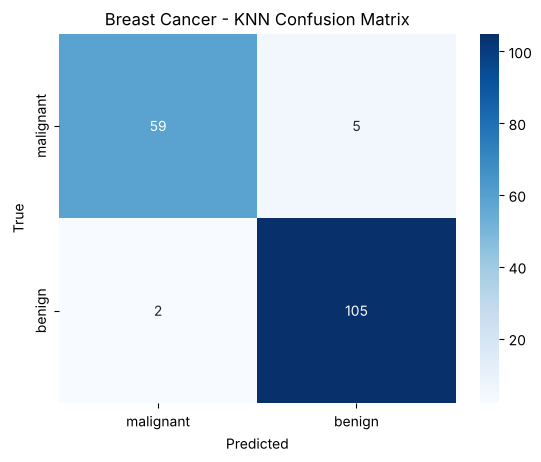

In [14]:
yb_pred = gs.best_estimator_.predict(Xb_test)
print(classification_report(yb_test, yb_pred, target_names=bc.target_names))

sns.heatmap(confusion_matrix(yb_test, yb_pred), annot=True, fmt='d', cmap='Blues',
            xticklabels=bc.target_names, yticklabels=bc.target_names)
plt.xlabel('Predicted'); plt.ylabel('True'); plt.title('Breast Cancer - KNN Confusion Matrix')
plt.show()

**Going further (book):** use distance metrics for clustering/regression and explore DBSCAN, mean shift, spectral clustering, kernel density and the radius-neighbours classifier — all available in scikit-learn.

---
### Chapter 4 key takeaways
1. KNN classifies by similarity: majority vote among the *k* nearest points under a chosen distance metric.
2. The metric (Euclidean / Manhattan / Minkowski), *k* and `weights` are hyperparameters — tune them with cross-validated grid or randomized search.
3. Scale features before KNN, and evaluate with more than accuracy (confusion matrix, precision, recall, F1, learning curves).